# Tarea 1 — Preparación del dataset IMDB (Unidad 4)
Clasificación de sentimiento (0 = negativo, 1 = positivo) con red neuronal, Ruta 3 (PLN con embeddings).
Este notebook solo prepara los datos (carga, exploración, vectorización y partición sin fuga). El entrenamiento del modelo se hace en la tarea 3, que continúa desde las variables finales de la última celda.

## 0. Configuración
Constantes del experimento, semillas fijas (Python, NumPy y TensorFlow) y versiones de las librerías para poder reproducir los resultados. `MAX_LEN` se deja en `None` porque se calcula más adelante usando solo datos de entrenamiento.

In [1]:
import os, re, string, sys, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # menos ruido de TensorFlow en las salidas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import datasets
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# ---- Constantes ----
SEED = 42
VAL_SIZE = 0.20      # fracción tomada del split train
MAX_TOKENS = 20000   # tamaño del vocabulario
MAX_LEN = None       # se calcula con estadísticas de TRAIN (sección c)
BATCH_SIZE = 64

# ---- Semillas ----
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)  # fija semillas de Python, NumPy y TensorFlow

print("python     :", sys.version.split()[0])
print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("datasets   :", datasets.__version__)
print(f"SEED={SEED} | VAL_SIZE={VAL_SIZE} | MAX_TOKENS={MAX_TOKENS} | BATCH_SIZE={BATCH_SIZE}")

/Users/steedwar/.gemini/antigravity/brain/8f053442-c815-4c88-9b98-84d597f61e6d/scratch/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


/Users/steedwar/.gemini/antigravity/brain/8f053442-c815-4c88-9b98-84d597f61e6d/scratch/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python     : 3.9.6
tensorflow : 2.19.1
keras      : 3.10.0
datasets   : 4.5.0
SEED=42 | VAL_SIZE=0.2 | MAX_TOKENS=20000 | BATCH_SIZE=64


## (a) Carga del dataset
Se carga IMDB desde Hugging Face. Si el dataset trae el split `unsupervised` se ignora: solo se usan `train` y `test`.

In [2]:
ds = load_dataset("stanfordnlp/imdb")
print(ds)

# Solo train y test (se ignora "unsupervised" si existe)
ds_train, ds_test = ds["train"], ds["test"]
print("\nSplits usados:", ["train", "test"], "| ignorados:", [s for s in ds.keys() if s not in ("train", "test")])
print("Features:", ds_train.features)

texts_train_all = list(ds_train["text"])
labels_train_all = np.array(ds_train["label"])
texts_test = list(ds_test["text"])
y_test = np.array(ds_test["label"])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

Splits usados: ['train', 'test'] | ignorados: ['unsupervised']
Features: {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


## (b) Exploración de datos
Se revisan tamaños, balance de clases, longitud de las reseñas (en caracteres y en palabras separadas por espacios), ejemplos crudos y calidad básica de los textos.

In [3]:
# 1. Número de ejemplos
print(f"Ejemplos train: {len(texts_train_all)}")
print(f"Ejemplos test : {len(texts_test)}")

Ejemplos train: 25000
Ejemplos test : 25000


TRAIN
   clase  conteo  porcentaje
0 (neg)   12500        50.0
1 (pos)   12500        50.0

TEST
   clase  conteo  porcentaje
0 (neg)   12500        50.0
1 (pos)   12500        50.0


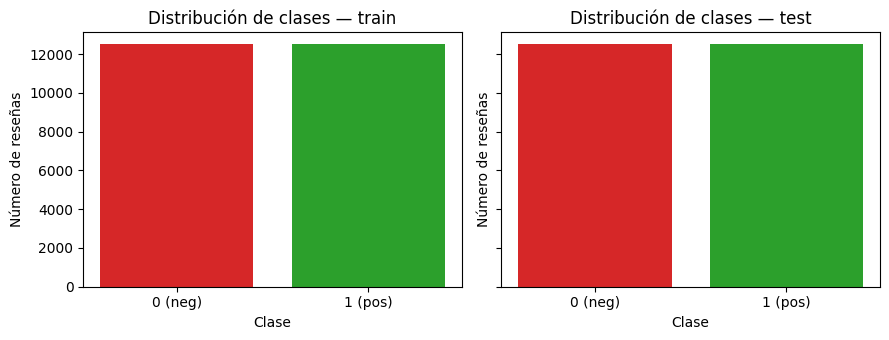

In [4]:
# 2. Distribución de clases
def dist_clases(y):
    c = pd.Series(y).value_counts().sort_index()
    return pd.DataFrame({"clase": ["0 (neg)", "1 (pos)"], "conteo": c.values, "porcentaje": (100 * c / c.sum()).round(2).values})

dist_tr, dist_te = dist_clases(labels_train_all), dist_clases(y_test)
print("TRAIN\n", dist_tr.to_string(index=False))
print("\nTEST\n", dist_te.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, d, nombre in zip(axes, (dist_tr, dist_te), ("train", "test")):
    ax.bar(d["clase"], d["conteo"], color=["tab:red", "tab:green"])
    ax.set_title(f"Distribución de clases — {nombre}")
    ax.set_xlabel("Clase"); ax.set_ylabel("Número de reseñas")
plt.tight_layout(); plt.show()

TRAIN
        caracteres  palabras
count     25000.0   25000.0
mean       1325.1     233.8
std        1003.1     173.7
min          52.0      10.0
50%         979.0     174.0
90%        2617.0     458.0
95%        3432.0     598.0
99%        5213.0     913.0
max       13704.0    2470.0

TEST
        caracteres  palabras
count     25000.0   25000.0
mean       1293.8     228.5
std         975.9     168.9
min          32.0       4.0
50%         962.0     172.0
90%        2544.1     444.0
95%        3333.0     582.0
99%        5138.1     901.0
max       12988.0    2278.0


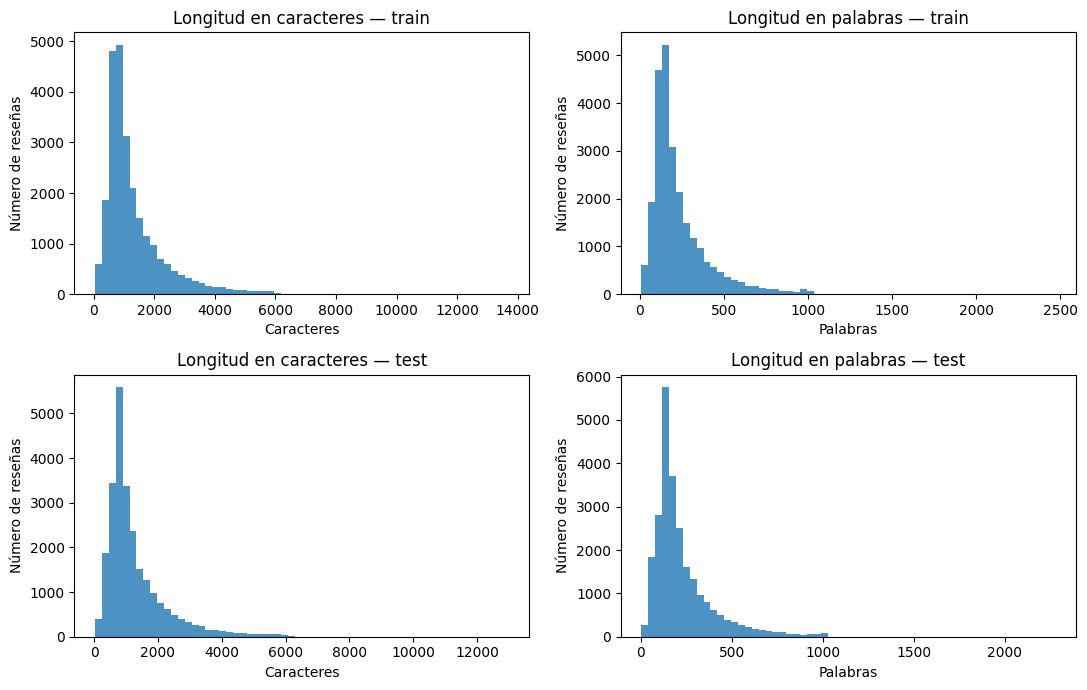

In [5]:
# 3. Longitud de los textos (caracteres y palabras separadas por espacios)
def longitudes(texts):
    return pd.DataFrame({"caracteres": [len(t) for t in texts], "palabras": [len(t.split()) for t in texts]})

len_tr, len_te = longitudes(texts_train_all), longitudes(texts_test)
pcts = [0.5, 0.9, 0.95, 0.99]
print("TRAIN\n", len_tr.describe(percentiles=pcts).round(1).to_string())
print("\nTEST\n", len_te.describe(percentiles=pcts).round(1).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, (d, nombre) in enumerate(((len_tr, "train"), (len_te, "test"))):
    for j, col in enumerate(("caracteres", "palabras")):
        axes[i, j].hist(d[col], bins=60, color="tab:blue", alpha=0.8)
        axes[i, j].set_title(f"Longitud en {col} — {nombre}")
        axes[i, j].set_xlabel(col.capitalize()); axes[i, j].set_ylabel("Número de reseñas")
plt.tight_layout(); plt.show()

In [6]:
# 4. Dos ejemplos crudos (uno por clase), truncados a ~300 caracteres
for etiqueta, nombre in ((1, "POSITIVO"), (0, "NEGATIVO")):
    i = int(np.where(labels_train_all == etiqueta)[0][0])
    print(f"[{nombre}] índice {i}: {texts_train_all[i][:300]!r}\n")

[POSITIVO] índice 12500: "Zentropa has much in common with The Third Man, another noir-like film set among the rubble of postwar Europe. Like TTM, there is much inventive camera work. There is an innocent American who gets emotionally involved with a woman he doesn't really understand, and whose naivety is all the more strik"

[NEGATIVO] índice 0: 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h'



In [7]:
# 5. ¿train viene ordenado por etiqueta?
ordenado_train = bool(np.all(np.diff(labels_train_all) >= 0))
cambios = int(np.sum(np.diff(labels_train_all) != 0))
print("train ordenado por etiqueta (no decreciente):", ordenado_train)
print("Cambios de etiqueta a lo largo de train     :", cambios)
print("Primeras 5 etiquetas:", labels_train_all[:5], "| últimas 5:", labels_train_all[-5:])
print("test ordenado por etiqueta                  :", bool(np.all(np.diff(y_test) >= 0)))

train ordenado por etiqueta (no decreciente): True
Cambios de etiqueta a lo largo de train     : 1
Primeras 5 etiquetas: [0 0 0 0 0] | últimas 5: [1 1 1 1 1]
test ordenado por etiqueta                  : True


**Orden por etiqueta.** Según la celda anterior, `train` viene ordenado por etiqueta (primero todas las reseñas negativas y luego todas las positivas, con un único cambio de etiqueta). Por eso es obligatorio mezclar (`shuffle=True`) antes de dividir en entrenamiento y validación: de lo contrario la validación saldría de un solo bloque y quedaría con una sola clase.

In [8]:
# 6. Textos vacíos o nulos
for nombre, textos in (("train", texts_train_all), ("test", texts_test)):
    nulos = sum(t is None for t in textos)
    vacios = sum((t is not None) and (t.strip() == "") for t in textos)
    print(f"{nombre}: nulos={nulos} | vacíos={vacios}")
    assert nulos == 0 and vacios == 0

train: nulos=0 | vacíos=0
test: nulos=0 | vacíos=0


## (c) Preprocesamiento: tokenización y secuencias con padding
Se usa `keras.layers.TextVectorization`, que tokeniza, construye el vocabulario y devuelve secuencias de enteros con padding/truncado. La estandarización es una función determinista sin parámetros aprendidos (minúsculas, `<br />` → espacio, sin puntuación, espacios normalizados), así que no produce fuga de datos. Se aplica antes de quitar la puntuación el reemplazo de `<br />`; de lo contrario quedarían tokens basura como `br`. Efecto colateral aceptado: los apóstrofes se eliminan (`don't` → `dont`).

**Orden de operaciones.** El vocabulario debe ajustarse solo con el subconjunto de entrenamiento final, es decir *después* de separar la validación. Por eso el primer paso de esta sección es la separación por índices (paso 1 de la sección d); la auditoría y los `tf.data` quedan en (d).

In [9]:
# (d.1, ejecutado aquí porque adapt() debe ir después) Separar train en train_final y validación, por ÍNDICES
all_idx = np.arange(len(texts_train_all))
train_idx, val_idx = train_test_split(
    all_idx, test_size=VAL_SIZE, stratify=labels_train_all, shuffle=True, random_state=SEED
)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)  # orden fijo para auditar; el barajado de entrenamiento se hace en tf.data

texts_train = [texts_train_all[i] for i in train_idx]; y_train = labels_train_all[train_idx]
texts_val   = [texts_train_all[i] for i in val_idx];   y_val   = labels_train_all[val_idx]
print(f"train_final={len(texts_train)} | validación={len(texts_val)} | test={len(texts_test)}")

train_final=20000 | validación=5000 | test=25000


In [10]:
# Estandarización determinista (sin parámetros aprendidos => sin fuga)
PUNCT_RE = "[" + re.escape(string.punctuation) + "]"

@keras.saving.register_keras_serializable(package="taller")
def estandarizar(x):
    x = tf.strings.lower(x)
    x = tf.strings.regex_replace(x, "<br />", " ")   # primero <br />, luego la puntuación
    x = tf.strings.regex_replace(x, PUNCT_RE, "")
    x = tf.strings.regex_replace(x, r"\s+", " ")
    return tf.strings.strip(x)

print(estandarizar(tf.constant("Great MOVIE!<br /><br />I loved it, don't miss   it.")).numpy().decode())

great movie i loved it dont miss it


Longitud en tokens (train_final): media=230.0 | mediana=172 | p90=451.0 | p95=585.0 | p99=907.0 | max=2459
MAX_LEN elegido = 585
Porcentaje de reseñas de train_final que se truncan con MAX_LEN: 4.96%


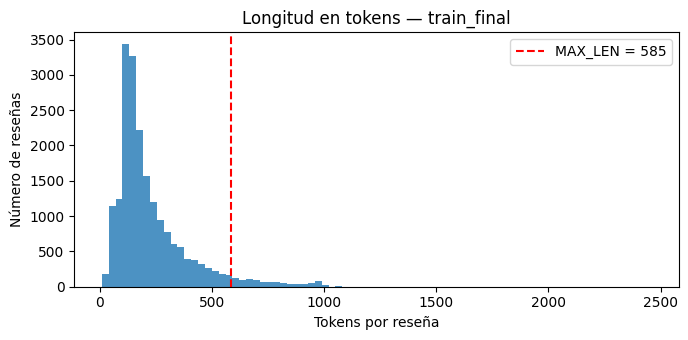

In [11]:
# MAX_LEN a partir SOLO de train_final: percentil 95 de longitud en tokens (texto ya estandarizado)
# Se tokeniza con tf.strings.split (misma regla de separación que usa TextVectorization con split="whitespace")
tokens_rag = tf.strings.split(estandarizar(tf.constant(texts_train)))
tok_len_train = tokens_rag.row_lengths().numpy()

p95 = float(np.percentile(tok_len_train, 95))
MAX_LEN = int(round(p95))
print(f"Longitud en tokens (train_final): media={tok_len_train.mean():.1f} | mediana={np.median(tok_len_train):.0f} | p90={np.percentile(tok_len_train, 90):.1f} | p95={p95:.1f} | p99={np.percentile(tok_len_train, 99):.1f} | max={tok_len_train.max()}")
print(f"MAX_LEN elegido = {MAX_LEN}")
print(f"Porcentaje de reseñas de train_final que se truncan con MAX_LEN: {100 * np.mean(tok_len_train > MAX_LEN):.2f}%")

plt.figure(figsize=(7, 3.5))
plt.hist(tok_len_train, bins=80, color="tab:blue", alpha=0.8)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Longitud en tokens — train_final"); plt.xlabel("Tokens por reseña"); plt.ylabel("Número de reseñas")
plt.legend(); plt.tight_layout(); plt.show()

**Justificación de `MAX_LEN`.** Se eligió el percentil 95 de la longitud en tokens de `train_final`: el valor es 585 tokens (p95 = 585.0), frente a una mediana de 172 y un máximo de 2459; con ese tope solo se truncan 4.96% de las reseñas de `train_final`. Así se conserva la reseña completa en la gran mayoría de casos, sin que unas pocas reseñas muy largas disparen el tamaño de todas las secuencias (memoria y tiempo de entrenamiento). La estadística se calculó solo con `train_final`.

In [12]:
# adapt() SOLO con los textos de train_final
vectorizer = keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize=estandarizar,
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_LEN,
)

textos_adapt = texts_train  # único objeto que se pasa a adapt()
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(textos_adapt).batch(BATCH_SIZE))

vocab = [str(w) for w in vectorizer.get_vocabulary()]
print("Tamaño real del vocabulario:", len(vocab), f"(MAX_TOKENS={MAX_TOKENS}; incluye '' = padding y '[UNK]')")
print("Primeros 20 tokens:", vocab[:20])

Tamaño real del vocabulario: 20000 (MAX_TOKENS=20000; incluye '' = padding y '[UNK]')
Primeros 20 tokens: ['', '[UNK]', 'the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this', 'that', 'was', 'as', 'for', 'with', 'movie', 'but', 'film']


In [13]:
# Transformar train_final, validación y test con el vectorizador YA ajustado
def vectorizar(textos):
    return vectorizer(tf.constant(textos)).numpy().astype("int32")

X_train, X_val, X_test = vectorizar(texts_train), vectorizar(texts_val), vectorizar(texts_test)
for nombre, X in (("X_train", X_train), ("X_val", X_val), ("X_test", X_test)):
    print(nombre, X.shape, X.dtype)

X_train (20000, 585) int32
X_val (5000, 585) int32
X_test (25000, 585) int32


In [14]:
# Demostración: reseña cruda -> secuencia de enteros (con padding) -> decodificación a tokens
ej = 3
print("RESEÑA CRUDA:\n", texts_train[ej][:300], "...\n")
print("SECUENCIA (primeros 40 de", MAX_LEN, "):", X_train[ej][:40])
print("SECUENCIA (últimos 10):", X_train[ej][-10:])
print("\nDECODIFICADA (primeros 40):", [vocab[i] for i in X_train[ej][:40]])
print("DECODIFICADA (últimos 10)  :", [vocab[i] for i in X_train[ej][-10:]], "(token '' = padding)")
print("Tokens no-padding en este ejemplo:", int((X_train[ej] != 0).sum()))

RESEÑA CRUDA:
 Whoever wrote the screenplay for this movie obviously never consulted any books about Lucille Ball, especially her autobiography. I've never seen so many mistakes in a biopic, ranging from her early years in Celoron and Jamestown to her later years with Desi. I could write a whole list of factual er ...

SECUENCIA (primeros 40 de 585 ): [2443 1098    2  848   15   11   17  520  109    1   99 1096   42 7461
 1946  260   39 8722  191  109  105   37  106 2437    8    4 6885 9251
   35   39  406  147    8    1    3    1    6   39  294  147]
SECUENCIA (últimos 10): [0 0 0 0 0 0 0 0 0 0]

DECODIFICADA (primeros 40): ['whoever', 'wrote', 'the', 'screenplay', 'for', 'this', 'movie', 'obviously', 'never', '[UNK]', 'any', 'books', 'about', 'lucille', 'ball', 'especially', 'her', 'autobiography', 'ive', 'never', 'seen', 'so', 'many', 'mistakes', 'in', 'a', 'biopic', 'ranging', 'from', 'her', 'early', 'years', 'in', '[UNK]', 'and', '[UNK]', 'to', 'her', 'later', 'years']
DECODIFICAD

In [15]:
# Porcentaje de tokens fuera de vocabulario ([UNK], índice 1) por partición
# (calculado sobre los tokens dentro de la ventana MAX_LEN, sin contar padding)
UNK_ID, PAD_ID = vocab.index("[UNK]"), vocab.index("")
def pct_unk(X):
    reales = (X != PAD_ID).sum()
    return 100 * (X == UNK_ID).sum() / reales

unk_pct = {"train_final": pct_unk(X_train), "validación": pct_unk(X_val), "test": pct_unk(X_test)}
for k, val in unk_pct.items():
    print(f"% [UNK] en {k:12s}: {val:.3f}%")

% [UNK] en train_final : 3.291%
% [UNK] en validación  : 3.638%
% [UNK] en test        : 4.043%


**Lectura del % de [UNK].** El vocabulario sale solo de `train_final`, así que `train_final` tiene el menor porcentaje de [UNK] (parte de él se pierde por el tope `MAX_TOKENS`), mientras que validación y test, que el vectorizador nunca vio al ajustarse, tienen un porcentaje parecido entre sí y mayor. Si el vocabulario se hubiera construido con validación o test, esa diferencia no aparecería.

## (d) Validación sin fuga de datos
Orden aplicado: (1) separar `train` en `train_final` y validación con `train_test_split` estratificado sobre índices, (2) `adapt()` solo con `train_final`, (3) transformar las tres particiones con el vectorizador ya ajustado. Los pasos 1 a 3 se ejecutaron en la sección (c); aquí se audita que no hubo fuga y se construyen los pipelines `tf.data`.

Sobre duplicados: IMDB contiene reseñas repetidas. Aquí **solo se reportan**; no se elimina ninguna, de modo que los tamaños de partición son los del dataset original. Las cifras reales están en la auditoría de más abajo: 99 textos de `train_final` también aparecen en test, y 34 aparecen también en validación. Son pocos frente al tamaño de las particiones, pero conviene tenerlo presente al interpretar las métricas de test.

In [16]:
# Tamaños y distribución de clases por partición
def resumen_clases(y):
    n = len(y); n1 = int(np.sum(y == 1)); n0 = n - n1
    return {"n": n, "neg": n0, "pos": n1, "%neg": round(100 * n0 / n, 2), "%pos": round(100 * n1 / n, 2)}

part = pd.DataFrame({"train_final": resumen_clases(y_train), "validación": resumen_clases(y_val), "test": resumen_clases(y_test)}).T
print(part.to_string())

                   n      neg      pos  %neg  %pos
train_final  20000.0  10000.0  10000.0  50.0  50.0
validación    5000.0   2500.0   2500.0  50.0  50.0
test         25000.0  12500.0  12500.0  50.0  50.0


In [17]:
# ===== Auditoría anti-fuga =====
s_tr, s_va = set(train_idx.tolist()), set(val_idx.tolist())

# 1. Índices disjuntos
inter = s_tr & s_va
print("Intersección de índices train_final ∩ validación:", len(inter))
assert len(inter) == 0

# 2. La validación proviene solo del split train original; train_final + validación = todo train, sin test
assert s_va <= set(range(len(ds_train))) and s_tr <= set(range(len(ds_train)))
assert s_tr | s_va == set(range(len(ds_train))) and len(s_tr) + len(s_va) == len(ds_train)
assert len(texts_test) == len(ds_test)  # test es un split aparte, no participa en la partición
print("train_final + validación cubren exactamente el split train original:", len(s_tr) + len(s_va), "=", len(ds_train))

# 3. Duplicados exactos (solo se reportan, no se eliminan)
st_tr, st_va, st_te = set(texts_train), set(texts_val), set(texts_test)
dup_tr_te = len(st_tr & st_te); dup_tr_va = len(st_tr & st_va)
print("Textos duplicados exactos (únicos) train_final ∩ test       :", dup_tr_te)
print("Textos duplicados exactos (únicos) train_final ∩ validación :", dup_tr_va)
print("Filas de test cuyo texto está en train_final                :", sum(t in st_tr for t in texts_test))
print("Filas de validación cuyo texto está en train_final          :", sum(t in st_tr for t in texts_val))

# 4. El vocabulario proviene únicamente de train_final
assert textos_adapt is texts_train and len(textos_adapt) == len(train_idx)
assert all(a == texts_train_all[i] for a, i in zip(textos_adapt, train_idx))   # adapt recibió exactamente los textos de train_idx
tokens_train = set(b.decode("utf-8") for b in tf.unique(tokens_rag.flat_values)[0].numpy())
vocab_sin_especiales = [w for w in vocab if w not in ("", "[UNK]")]
fuera = [w for w in vocab_sin_especiales if w not in tokens_train]
print("adapt() se llamó con", len(textos_adapt), "textos, todos de train_idx")
print("Tokens del vocabulario que NO aparecen en train_final:", len(fuera))
assert len(fuera) == 0
print("\nAUDITORÍA OK: sin fuga entre train_final, validación y test")

Intersección de índices train_final ∩ validación: 0
train_final + validación cubren exactamente el split train original: 25000 = 25000
Textos duplicados exactos (únicos) train_final ∩ test       : 99
Textos duplicados exactos (únicos) train_final ∩ validación : 34
Filas de test cuyo texto está en train_final                : 99
Filas de validación cuyo texto está en train_final          : 35


adapt() se llamó con

 20000 textos, todos de train_idx
Tokens del vocabulario que NO aparecen en train_final: 0

AUDITORÍA OK: sin fuga entre train_final, validación y test


In [18]:
# Pipelines tf.data
train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train.astype("int32")))
            .shuffle(buffer_size=len(X_train), seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds  = (tf.data.Dataset.from_tensor_slices((X_val, y_val.astype("int32")))
           .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
test_ds = (tf.data.Dataset.from_tensor_slices((X_test, y_test.astype("int32")))
           .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

print("train_ds element_spec:", train_ds.element_spec)
print("val_ds   element_spec:", val_ds.element_spec)
print("test_ds  element_spec:", test_ds.element_spec)

xb, yb = next(iter(train_ds))
print(f"Batch de train_ds: X={tuple(xb.shape)} (batch, MAX_LEN) | y={tuple(yb.shape)} (batch,)")
assert xb.shape == (BATCH_SIZE, MAX_LEN) and yb.shape == (BATCH_SIZE,)
print("Batches por época -> train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

train_ds element_spec: (TensorSpec(shape=(None, 585), dtype=tf.int32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
val_ds   element_spec: (TensorSpec(shape=(None, 585), dtype=tf.int32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
test_ds  element_spec: (TensorSpec(shape=(None, 585), dtype=tf.int32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


Batch de train_ds: X=(64, 585) (batch, MAX_LEN) | y=(64,) (batch,)
Batches por época -> train: 313 | val: 79 | test: 391


## Resumen final y variables para la tarea 3
Variables reutilizables: `vectorizer`, `train_ds`, `val_ds`, `test_ds`, `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test`, `train_idx`, `val_idx`, `MAX_LEN`, `MAX_TOKENS`.

In [19]:
resumen = pd.DataFrame({
    "n": [len(y_train), len(y_val), len(y_test)],
    "negativas": [int((y_train == 0).sum()), int((y_val == 0).sum()), int((y_test == 0).sum())],
    "positivas": [int((y_train == 1).sum()), int((y_val == 1).sum()), int((y_test == 1).sum())],
    "% positivas": [round(100 * y.mean(), 2) for y in (y_train, y_val, y_test)],
    "% [UNK]": [round(unk_pct[k], 3) for k in ("train_final", "validación", "test")],
    "forma X": [str(X_train.shape), str(X_val.shape), str(X_test.shape)],
}, index=["train_final", "validación", "test"])
print(resumen.to_string())
print()
print("MAX_LEN            :", MAX_LEN)
print("MAX_TOKENS         :", MAX_TOKENS)
print("Vocabulario real   :", len(vocab))
print("SEED               :", SEED)
print("BATCH_SIZE         :", BATCH_SIZE)
print("len(train_idx), len(val_idx):", len(train_idx), len(val_idx))

                 n  negativas  positivas  % positivas  % [UNK]       forma X
train_final  20000      10000      10000         50.0    3.291  (20000, 585)
validación    5000       2500       2500         50.0    3.638   (5000, 585)
test         25000      12500      12500         50.0    4.043  (25000, 585)

MAX_LEN            : 585
MAX_TOKENS         : 20000
Vocabulario real   : 20000
SEED               : 42
BATCH_SIZE         : 64
len(train_idx), len(val_idx): 20000 5000


## Tarea 3 — Entrenamiento del modelo base (Unidad 4)
Se entrena la primera configuración: `Embedding` + `GlobalAveragePooling1D` + `Dense` (capa oculta ReLU) + salida sigmoide para clasificar sentimiento.
El modelo se ajusta **solo con `train_final`** (`X_train`, `y_train`) y se valida con el conjunto de **validación** separado en la tarea 1 (`X_val`, `y_val`).
El conjunto de **test no se usa en esta tarea**; se reserva para la evaluación final (tarea 5).
Se entrenan las 10 épocas completas, sin EarlyStopping, para dejar visible el comportamiento real (incluido el posible sobreajuste).

### Hiperparámetros

In [20]:
# Hiperparámetros del modelo base (constantes visibles)
# SEED y BATCH_SIZE ya están definidos en la configuración (celda 0); aquí se reutilizan, no se redefinen.
# MAX_LEN, MAX_TOKENS y el vocabulario vienen de la tarea 1 (no se recalculan).
EMBEDDING_DIM = 32
EPOCHS = 10
OPTIMIZER_NAME = "Adam"
LEARNING_RATE = 1e-3
LOSS = "binary_crossentropy"
METRICS = ["accuracy"]
DENSE_UNITS = 16            # capa oculta con activación ReLU
VOCAB_SIZE = len(vocab)     # tamaño del vocabulario de la tarea 1 (incluye '' = padding y [UNK])

# Reproducibilidad: se vuelven a fijar las semillas justo antes de construir el modelo
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)  # Python, NumPy y TensorFlow

print("===== HIPERPARÁMETROS DEL MODELO BASE =====")
print(f"Épocas (EPOCHS)          : {EPOCHS}")
print(f"Batch size (BATCH_SIZE)  : {BATCH_SIZE}")
print(f"Optimizador              : {OPTIMIZER_NAME}")
print(f"Learning rate            : {LEARNING_RATE}")
print(f"Función de pérdida       : {LOSS}")
print(f"Métricas                 : {METRICS}")
print(f"Dimensión del embedding  : {EMBEDDING_DIM}")
print(f"Unidades capa densa      : {DENSE_UNITS} (ReLU)")
print(f"Tamaño de vocabulario    : {VOCAB_SIZE}")
print(f"Longitud de secuencia    : {MAX_LEN}")
print(f"Semilla (SEED)           : {SEED}")

===== HIPERPARÁMETROS DEL MODELO BASE =====
Épocas (EPOCHS)          : 10
Batch size (BATCH_SIZE)  : 64
Optimizador              : Adam
Learning rate            : 0.001
Función de pérdida       : binary_crossentropy
Métricas                 : ['accuracy']
Dimensión del embedding  : 32
Unidades capa densa      : 16 (ReLU)
Tamaño de vocabulario    : 20000
Longitud de secuencia    : 585
Semilla (SEED)           : 42


### Arquitectura

In [21]:
# Padding = índice 0 (token '' del vocabulario), por eso se activa mask_zero=True
assert vocab[0] == "" and PAD_ID == 0

modelo_base = keras.Sequential([
    keras.Input(shape=(MAX_LEN,), dtype="int32"),
    keras.layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True),
    keras.layers.GlobalAveragePooling1D(),
    keras.layers.Dense(DENSE_UNITS, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
], name="modelo_base")

modelo_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=LOSS,
    metrics=METRICS,
)
modelo_base.summary()

Model: "modelo_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 585, 32)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 640,545 (2.44 MB)

 Trainable params: 640,545 (2.44 MB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento
Se usa el conjunto de validación explícito (`X_val`, `y_val`); sin `validation_split`, sin callbacks y sin test.

In [22]:
history_base = modelo_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
)

Epoch 1/10


313/313 - 1s - 3ms/step - accuracy: 0.7696 - loss: 0.5495 - val_accuracy: 0.8634 - val_loss: 0.3700


Epoch 2/10


313/313 - 1s - 2ms/step - accuracy: 0.8935 - loss: 0.2878 - val_accuracy: 0.8888 - val_loss: 0.2797


Epoch 3/10


313/313 - 1s - 2ms/step - accuracy: 0.9255 - loss: 0.2049 - val_accuracy: 0.8982 - val_loss: 0.2603


... (10 outputs left out)

Epoch 9/10


313/313 - 1s - 2ms/step - accuracy: 0.9936 - loss: 0.0381 - val_accuracy: 0.8940 - val_loss: 0.3453


Epoch 10/10


313/313 - 1s - 2ms/step - accuracy: 0.9968 - loss: 0.0274 - val_accuracy: 0.8914 - val_loss: 0.3734


### Registro por época (entrenamiento vs. validación)

In [23]:
df_historial_base = pd.DataFrame({
    "epoca": range(1, len(history_base.history["loss"]) + 1),
    "loss": history_base.history["loss"],
    "accuracy": history_base.history["accuracy"],
    "val_loss": history_base.history["val_loss"],
    "val_accuracy": history_base.history["val_accuracy"],
})

print(df_historial_base.round(4).to_string(index=False))

mejor = df_historial_base.loc[df_historial_base["val_loss"].idxmin()]
final = df_historial_base.iloc[-1]
print(f"\nÉpoca con menor val_loss: {int(mejor['epoca'])} (val_loss={mejor['val_loss']:.4f}, val_accuracy={mejor['val_accuracy']:.4f})")
print(f"Final (época {int(final['epoca'])}) - loss      train={final['loss']:.4f} | val={final['val_loss']:.4f}")
print(f"Final (época {int(final['epoca'])}) - accuracy  train={final['accuracy']:.4f} | val={final['val_accuracy']:.4f}")

 epoca   loss  accuracy  val_loss  val_accuracy
     1 0.5495    0.7696    0.3700        0.8634
     2 0.2878    0.8935    0.2797        0.8888
     3 0.2049    0.9255    0.2603        0.8982
     4 0.1569    0.9481    0.2585        0.9008
     5 0.1214    0.9628    0.2654        0.9020
     6 0.0933    0.9737    0.2785        0.9010
     7 0.0705    0.9833    0.2972        0.9000
     8 0.0523    0.9896    0.3199        0.8992
     9 0.0381    0.9936    0.3453        0.8940
    10 0.0274    0.9968    0.3734        0.8914

Época con menor val_loss: 4 (val_loss=0.2585, val_accuracy=0.9008)
Final (época 10) - loss      train=0.0274 | val=0.3734
Final (época 10) - accuracy  train=0.9968 | val=0.8914
